CUSTOMER SPENDING PREDICTION
Dataset Shape: (1000, 36)

Numerical Features:
['Age', 'Frequency_of_Purchase', 'Brand_Loyalty', 'Product_Rating', 'Time_Spent_on_Product_Research(hours)', 'Return_Rate', 'Customer_Satisfaction', 'Time_to_Decision', 'Purchase_Year', 'Purchase_Month', 'Purchase_Day', 'Purchase_DayOfWeek', 'Purchase_Hour', 'Spending_per_Purchase_Frequency', 'Engagement_Score', 'Research_to_Decision_Ratio']

Categorical Features:
['Gender', 'Income_Level', 'Marital_Status', 'Education_Level', 'Occupation', 'Location', 'Purchase_Category', 'Purchase_Channel', 'Social_Media_Influence', 'Discount_Sensitivity', 'Engagement_with_Ads', 'Device_Used_for_Shopping', 'Payment_Method', 'Purchase_Intent', 'Shipping_Preference']

Training Samples: 800
Testing Samples: 200

------------------------------------------------------------
Linear Regression
------------------------------------------------------------
MAE : 67.8523
MSE : 7348.0974
RMSE: 85.721
R²  : 0.578

------------------------

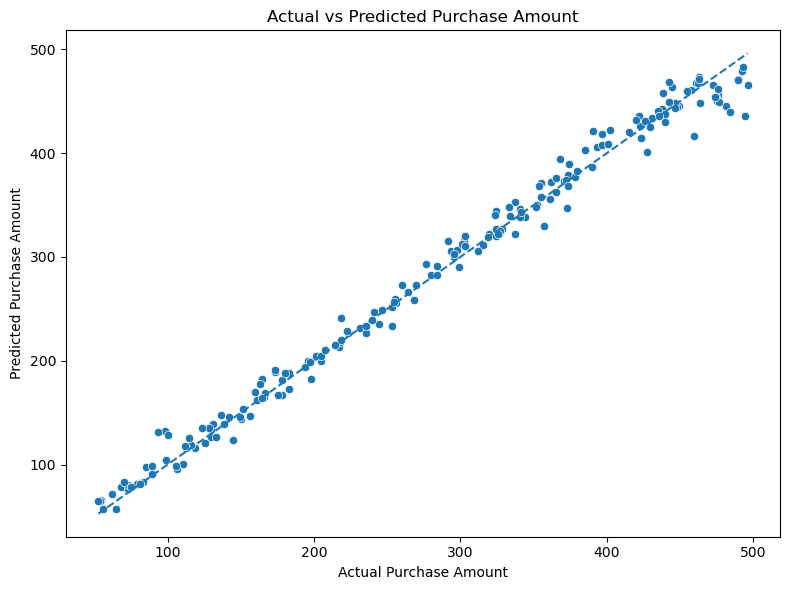

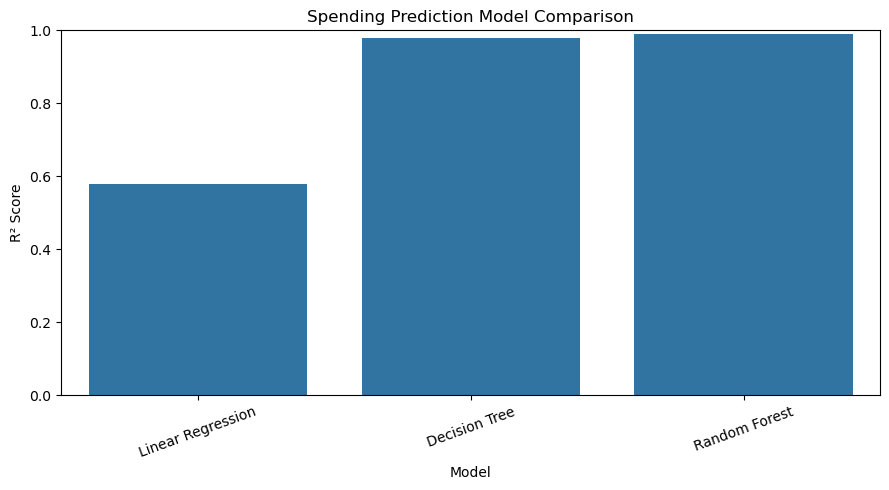


Spending prediction model saved to: ../models/spending_prediction.pkl

PROJECT OBJECTIVES STATUS
1. Predict customer spending       → COMPLETED
2. Classify purchase behavior      → COMPLETED
3. Segment customers into groups   → COMPLETED

E-COMMERCE CONSUMER BEHAVIOR ANALYSIS
FINAL ANALYSIS COMPLETED

Models generated:
• Customer Segmentation:
  ../models/customer_segmentation.pkl
• Purchase Behavior Prediction:
  ../models/purchase_prediction.pkl
• Spending Prediction:
  ../models/spending_prediction.pkl


In [1]:
# ============================================================
# STEP 8: CUSTOMER SPENDING PREDICTION
# REGRESSION + FINAL PROJECT ANALYSIS
# ============================================================

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# ------------------------------------------------------------
# 1. Load feature-engineered dataset
# ------------------------------------------------------------

df = pd.read_csv(
    "../data/processed/feature_engineered_data.csv"
)

print("=" * 60)
print("CUSTOMER SPENDING PREDICTION")
print("=" * 60)

print("Dataset Shape:", df.shape)


# ------------------------------------------------------------
# 2. Define target
# ------------------------------------------------------------

target = "Purchase_Amount"

y = df[target]

# Do not use target-related artificial features as inputs.
# Also remove Customer_Segment because it was generated
# by the clustering model.

drop_columns = [
    target,
    "Customer_Segment",
    "Time_of_Purchase"
]

X = df.drop(
    columns=drop_columns,
    errors="ignore"
)


# ------------------------------------------------------------
# 3. Identify feature types
# ------------------------------------------------------------

numerical_features = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_features = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("\nNumerical Features:")
print(numerical_features)

print("\nCategorical Features:")
print(categorical_features)


# ------------------------------------------------------------
# 4. Numerical preprocessing
# ------------------------------------------------------------

numerical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="median")
        ),
        (
            "scaler",
            StandardScaler()
        )
    ]
)


# ------------------------------------------------------------
# 5. Categorical preprocessing
# ------------------------------------------------------------

categorical_pipeline = Pipeline(
    steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore"
            )
        )
    ]
)


# ------------------------------------------------------------
# 6. Combine preprocessing
# ------------------------------------------------------------

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            numerical_pipeline,
            numerical_features
        ),
        (
            "cat",
            categorical_pipeline,
            categorical_features
        )
    ]
)


# ------------------------------------------------------------
# 7. Train-test split
# ------------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("\nTraining Samples:", X_train.shape[0])
print("Testing Samples:", X_test.shape[0])


# ------------------------------------------------------------
# 8. Regression models
# ------------------------------------------------------------

models = {
    "Linear Regression": LinearRegression(),

    "Decision Tree": DecisionTreeRegressor(
        random_state=42,
        max_depth=8
    ),

    "Random Forest": RandomForestRegressor(
        n_estimators=200,
        random_state=42,
        max_depth=12
    )
}


# ------------------------------------------------------------
# 9. Train and evaluate models
# ------------------------------------------------------------

results = {}
trained_models = {}

for name, model in models.items():

    pipeline = Pipeline(
        steps=[
            (
                "preprocessor",
                preprocessor
            ),
            (
                "model",
                model
            )
        ]
    )

    pipeline.fit(
        X_train,
        y_train
    )

    y_pred = pipeline.predict(
        X_test
    )

    mae = mean_absolute_error(
        y_test,
        y_pred
    )

    mse = mean_squared_error(
        y_test,
        y_pred
    )

    rmse = np.sqrt(mse)

    r2 = r2_score(
        y_test,
        y_pred
    )

    results[name] = {
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    }

    trained_models[name] = pipeline

    print("\n" + "-" * 60)
    print(name)
    print("-" * 60)

    print("MAE :", round(mae, 4))
    print("MSE :", round(mse, 4))
    print("RMSE:", round(rmse, 4))
    print("R²  :", round(r2, 4))


# ------------------------------------------------------------
# 10. Model comparison
# ------------------------------------------------------------

results_df = pd.DataFrame(
    results
).T.reset_index()

results_df = results_df.rename(
    columns={"index": "Model"}
)

print("\n" + "=" * 60)
print("REGRESSION MODEL COMPARISON")
print("=" * 60)

print(
    results_df.round(4)
)


# ------------------------------------------------------------
# 11. Select best model
# ------------------------------------------------------------

# Higher R² = better
best_model_name = results_df.loc[
    results_df["R2"].idxmax(),
    "Model"
]

best_model = trained_models[
    best_model_name
]

print(
    "\nBest Spending Prediction Model:",
    best_model_name
)

print(
    "Best R²:",
    round(
        results[best_model_name]["R2"],
        4
    )
)


# ------------------------------------------------------------
# 12. Actual vs Predicted
# ------------------------------------------------------------

best_predictions = best_model.predict(
    X_test
)

plt.figure(figsize=(8, 6))

sns.scatterplot(
    x=y_test,
    y=best_predictions
)

plt.xlabel("Actual Purchase Amount")
plt.ylabel("Predicted Purchase Amount")

plt.title(
    "Actual vs Predicted Purchase Amount"
)

min_value = min(
    y_test.min(),
    best_predictions.min()
)

max_value = max(
    y_test.max(),
    best_predictions.max()
)

plt.plot(
    [min_value, max_value],
    [min_value, max_value],
    linestyle="--"
)

plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 13. Model comparison graph
# ------------------------------------------------------------

plt.figure(figsize=(9, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="R2"
)

plt.title("Spending Prediction Model Comparison")
plt.xlabel("Model")
plt.ylabel("R² Score")

plt.ylim(
    min(0, results_df["R2"].min() - 0.1),
    1
)

plt.xticks(rotation=20)
plt.tight_layout()
plt.show()


# ------------------------------------------------------------
# 14. Save best spending prediction model
# ------------------------------------------------------------

model_path = (
    "../models/spending_prediction.pkl"
)

joblib.dump(
    best_model,
    model_path
)

print(
    "\nSpending prediction model saved to:",
    model_path
)


# ------------------------------------------------------------
# 15. Final project objectives
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("PROJECT OBJECTIVES STATUS")
print("=" * 60)

print("1. Predict customer spending       → COMPLETED")
print("2. Classify purchase behavior      → COMPLETED")
print("3. Segment customers into groups   → COMPLETED")


# ------------------------------------------------------------
# 16. Final project summary
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("E-COMMERCE CONSUMER BEHAVIOR ANALYSIS")
print("FINAL ANALYSIS COMPLETED")
print("=" * 60)

print("\nModels generated:")

print("• Customer Segmentation:")
print("  ../models/customer_segmentation.pkl")

print("• Purchase Behavior Prediction:")
print("  ../models/purchase_prediction.pkl")

print("• Spending Prediction:")
print("  ../models/spending_prediction.pkl")

In [2]:
# ============================================================
# STEP 9: FINAL PROJECT VALIDATION
# ============================================================

import os
import pandas as pd
import joblib

print("=" * 60)
print("FINAL PROJECT VALIDATION")
print("=" * 60)

# ------------------------------------------------------------
# 1. Check processed datasets
# ------------------------------------------------------------

processed_files = [
    "../data/processed/cleaned_ecommerce_data.csv",
    "../data/processed/feature_engineered_data.csv"
]

print("\nPROCESSED DATASETS")
print("-" * 40)

for file in processed_files:

    if os.path.exists(file):

        data = pd.read_csv(file)

        print(
            f"✓ {file} | Shape: {data.shape}"
        )

    else:

        print(f"✗ Missing: {file}")


# ------------------------------------------------------------
# 2. Check trained models
# ------------------------------------------------------------

model_files = [
    "../models/customer_segmentation.pkl",
    "../models/purchase_prediction.pkl",
    "../models/spending_prediction.pkl"
]

print("\nTRAINED MODELS")
print("-" * 40)

for file in model_files:

    if os.path.exists(file):

        print(f"✓ {file}")

        model = joblib.load(file)

        print(
            "  Type:",
            type(model)
        )

    else:

        print(f"✗ Missing: {file}")


# ------------------------------------------------------------
# 3. Check segmentation result
# ------------------------------------------------------------

feature_file = (
    "../data/processed/feature_engineered_data.csv"
)

df = pd.read_csv(feature_file)

print("\nCUSTOMER SEGMENTATION")
print("-" * 40)

if "Customer_Segment" in df.columns:

    print(
        "Number of Segments:",
        df["Customer_Segment"].nunique()
    )

    print("\nCustomers per Segment:")

    print(
        df["Customer_Segment"]
        .value_counts()
        .sort_index()
    )

else:

    print("✗ Customer_Segment column not found")


# ------------------------------------------------------------
# 4. Check purchase behavior target
# ------------------------------------------------------------

print("\nPURCHASE BEHAVIOR")
print("-" * 40)

if "Purchase_Intent" in df.columns:

    print(
        "Purchase Intent Classes:",
        df["Purchase_Intent"].nunique()
    )

    print(
        df["Purchase_Intent"]
        .value_counts()
    )

else:

    print("✗ Purchase_Intent column not found")


# ------------------------------------------------------------
# 5. Check spending target
# ------------------------------------------------------------

print("\nSPENDING ANALYSIS")
print("-" * 40)

if "Purchase_Amount" in df.columns:

    print(
        "Average Purchase Amount:",
        round(
            df["Purchase_Amount"].mean(),
            2
        )
    )

    print(
        "Minimum Purchase Amount:",
        round(
            df["Purchase_Amount"].min(),
            2
        )
    )

    print(
        "Maximum Purchase Amount:",
        round(
            df["Purchase_Amount"].max(),
            2
        )
    )


# ------------------------------------------------------------
# 6. Final status
# ------------------------------------------------------------

print("\n" + "=" * 60)
print("PROJECT VALIDATION COMPLETED")
print("=" * 60)

print("""
✓ Data preprocessing completed
✓ EDA completed
✓ Customer analysis completed
✓ Feature engineering completed
✓ Customer segmentation completed
✓ Purchase behavior classification completed
✓ Customer spending prediction completed
✓ Models saved
""")

print("Next Stage → Streamlit Dashboard")

FINAL PROJECT VALIDATION

PROCESSED DATASETS
----------------------------------------
✓ ../data/processed/cleaned_ecommerce_data.csv | Shape: (1000, 28)
✓ ../data/processed/feature_engineered_data.csv | Shape: (1000, 36)

TRAINED MODELS
----------------------------------------
✓ ../models/customer_segmentation.pkl
  Type: <class 'dict'>
✓ ../models/purchase_prediction.pkl
  Type: <class 'sklearn.pipeline.Pipeline'>
✓ ../models/spending_prediction.pkl
  Type: <class 'sklearn.pipeline.Pipeline'>

CUSTOMER SEGMENTATION
----------------------------------------
Number of Segments: 4

Customers per Segment:
Customer_Segment
0     63
1    361
2    361
3    215
Name: count, dtype: int64

PURCHASE BEHAVIOR
----------------------------------------
Purchase Intent Classes: 4
Purchase_Intent
Need-based     256
Wants-based    249
Impulsive      248
Planned        247
Name: count, dtype: int64

SPENDING ANALYSIS
----------------------------------------
Average Purchase Amount: 275.06
Minimum Purchas